**Лабораторная работа №5. Классификация**

**Цель работы:** изучение алгоритмов и методов классификации на практике: k-ближайших соседей, дерево решений, логистическая регрессия, случайный лес; оценка качества моделей с помощью метрик, матриц неточностей и ROC-кривых.

**Вариант №5** — набор данных `telecom_churn.csv` (информация о клиентах телеком-компании).

В работе выполняется полный цикл решения задачи бинарной классификации: загрузка и предварительная обработка данных, визуальный анализ, разбиение на обучающую и тестовую выборки, обучение четырёх моделей, сравнение их качества и формулировка выводов.

# 1. Загрузка набора данных

Используется набор `telecom_churn.csv`. Целевая переменная — `Churn`: 1 — клиент ушёл (расторг контракт), 0 — клиент остался. Остальные признаки описывают возраст, пол, тип контракта, способ оплаты, стаж обслуживания, платежи, активность звонков, обращения в поддержку, наличие международного плана и регион.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, balanced_accuracy_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
)

RANDOM_STATE = 5


In [2]:
df = pd.read_csv('telecom_churn.csv')
print('Размер набора данных:', df.shape)
display(df.head())
display(df.describe().T)


Размер набора данных: (3016, 12)


,age,gender,contract_type,payment_method,tenure_months,monthly_charges,total_charges,avg_call_minutes,num_support_tickets,has_international_plan,region,Churn
0,53,M,Month-to-month,Bank transfer,58,56.46,3448.16,206.9,0,No,North,0
1,18,F,Month-to-month,Electronic check,16,64.86,1227.48,345.3,2,Yes,West,1
2,81,M,Month-to-month,Electronic check,59,97.64,5773.27,242.8,0,No,North,0
3,65,F,One year,Credit card,16,27.90,416.11,257.2,0,Yes,North,0
4,40,F,Month-to-month,Electronic check,65,56.33,3805.53,205.1,1,No,North,0


,count,mean,std,min,25%,50%,75%,max
age,3016.0,51.519231,19.202550,18.00,35.7500,51.000,68.0000,84.000
tenure_months,3016.0,37.021220,21.228354,0.00,19.0000,37.000,55.0000,74.000
monthly_charges,3016.0,67.878336,26.120795,5.00,50.5575,67.170,84.8700,222.034
total_charges,3016.0,2499.773856,1797.004026,-84.31,1048.6300,2194.135,3677.9675,11620.220
avg_call_minutes,3016.0,249.071320,78.856929,20.00,196.4500,247.600,303.1000,499.600
num_support_tickets,3016.0,0.906830,1.016745,0.00,0.0000,1.000,1.0000,6.000
Churn,3016.0,0.159483,0.366186,0.00,0.0000,0.000,0.0000,1.000


**Интерпретация.** Набор данных содержит 3016 наблюдений и 12 столбцов. В данных представлены числовые признаки (`age`, `tenure_months`, `monthly_charges`, `total_charges`, `avg_call_minutes`, `num_support_tickets`), категориальные признаки (`gender`, `contract_type`, `payment_method`, `has_international_plan`, `region`) и целевая переменная `Churn`. Масштабы числовых признаков различаются: например, `total_charges` измеряется тысячами, а `num_support_tickets` — небольшими целыми значениями, поэтому перед обучением моделей, чувствительных к масштабу, потребуется стандартизация.

# 2. Предварительная обработка данных

Проверим пропуски, дубликаты, типы данных и корректность значений. Отдельно проверим `total_charges`: в наборе могут встречаться отрицательные значения, которые физически некорректны для накопленных платежей.

In [3]:
print('Типы данных:')
print(df.dtypes)
print('\nПропуски по столбцам:')
print(df.isna().sum())
print('\nЧисло полных дубликатов:', df.duplicated().sum())
print('\nЧисло отрицательных значений total_charges:', int((df['total_charges'] < 0).sum()))
print('\nУникальные значения категориальных признаков:')
for col in df.select_dtypes(include='object').columns:
    print(f'  {col}: {df[col].unique().tolist()}')


Типы данных:
age                         int64
gender                     object
contract_type              object
payment_method             object
tenure_months               int64
monthly_charges           float64
total_charges             float64
avg_call_minutes          float64
num_support_tickets         int64
has_international_plan     object
region                     object
Churn                       int64
dtype: object

Пропуски по столбцам:
age                       0
gender                    0
contract_type             0
payment_method            0
tenure_months             0
monthly_charges           0
total_charges             0
avg_call_minutes          0
num_support_tickets       0
has_international_plan    0
region                    0
Churn                     0
dtype: int64

Число полных дубликатов: 0

Число отрицательных значений total_charges: 26

Уникальные значения категориальных признаков:
  gender: ['M', 'F']
  contract_type: ['Month-to-month', 'One year', '

**Интерпретация.** Пропусков и полных дубликатов в наборе нет. Категориальные признаки имеют ожидаемые значения, опечаток и лишних категорий не обнаружено. При этом выявлено 26 отрицательных значений `total_charges`. Такие значения противоречат смыслу признака «накопленные платежи», поэтому их нужно корректно обработать до обучения моделей.

In [4]:
df_prep = df.copy()
negative_total = df_prep['total_charges'] < 0
print('Строк с отрицательным total_charges:', int(negative_total.sum()))

# Восстанавливаем накопленные платежи как monthly_charges * tenure_months
recalc = df_prep.loc[negative_total, 'monthly_charges'] * df_prep.loc[negative_total, 'tenure_months']
df_prep.loc[negative_total, 'total_charges'] = recalc

print('Диапазон восстановленных значений:', round(recalc.min(), 2), '-', round(recalc.max(), 2))
print('Минимальный total_charges после обработки:', round(df_prep['total_charges'].min(), 2))
print('Осталось отрицательных значений:', int((df_prep['total_charges'] < 0).sum()))


Строк с отрицательным total_charges: 26
Диапазон восстановленных значений: 0.0 - 273.81
Минимальный total_charges после обработки: 0.0
Осталось отрицательных значений: 0


**Интерпретация.** Отрицательные значения `total_charges` восстановлены по формуле `monthly_charges × tenure_months`. Это логичная замена, так как накопленные платежи должны согласовываться со стажем и ежемесячной оплатой. После обработки отрицательных значений не осталось, диапазон `total_charges` стал корректным.

# 3. Выделение целевой переменной и матрица диаграмм рассеяния

Целевая переменная `Churn` выделяется отдельно и не включается в матрицу признаков модели. Для визуального анализа построим матрицу диаграмм рассеяния числовых признаков, выделив классы `Churn` разными цветами.

In [5]:
y = df_prep['Churn']
X = df_prep.drop(columns=['Churn'])

num_cols = ['age', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_call_minutes', 'num_support_tickets']
cat_cols = ['gender', 'contract_type', 'payment_method', 'has_international_plan', 'region']

print('Целевая переменная: Churn')
print('Числовые признаки:', num_cols)
print('Категориальные признаки:', cat_cols)
print('Размер матрицы признаков:', X.shape)


Целевая переменная: Churn
Числовые признаки: ['age', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_call_minutes', 'num_support_tickets']
Категориальные признаки: ['gender', 'contract_type', 'payment_method', 'has_international_plan', 'region']
Размер матрицы признаков: (3016, 11)


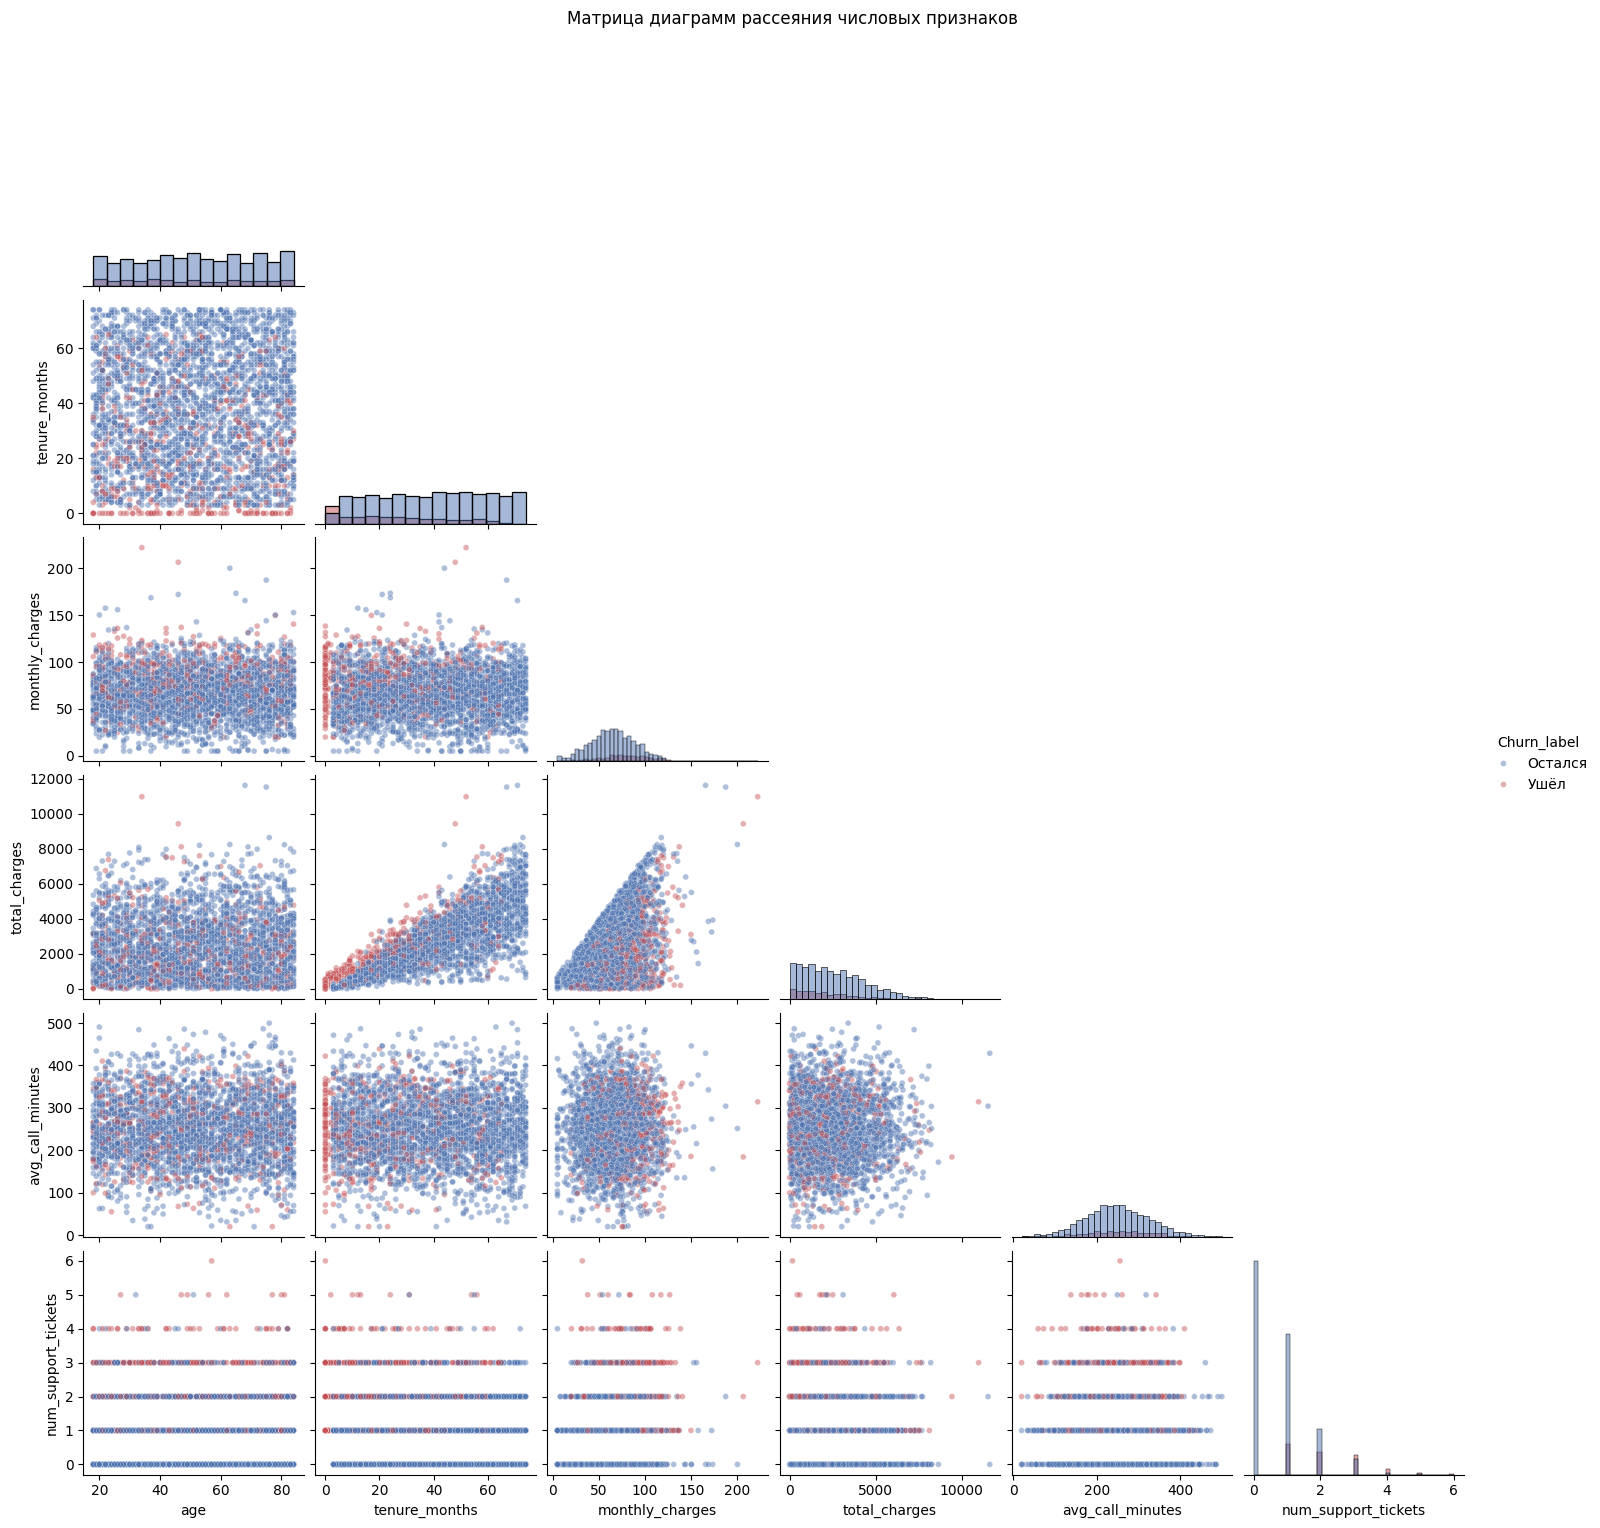

In [6]:
plot_df = df_prep[num_cols + ['Churn']].copy()
plot_df['Churn_label'] = plot_df['Churn'].map({0: 'Остался', 1: 'Ушёл'})

sns.pairplot(
    plot_df[num_cols + ['Churn_label']],
    hue='Churn_label',
    corner=True,
    diag_kind='hist',
    plot_kws={'alpha': 0.45, 's': 18},
    palette={'Остался': '#4C72B0', 'Ушёл': '#C44E52'}
)
plt.suptitle('Матрица диаграмм рассеяния числовых признаков', y=1.02)
plt.show()


**Интерпретация.** На диаграммах рассеяния ушедшие клиенты (`Churn = 1`) заметно чаще встречаются среди клиентов с небольшим стажем `tenure_months`, высокими ежемесячными платежами `monthly_charges` и большим числом обращений в поддержку `num_support_tickets`. Оставшиеся клиенты чаще имеют больший стаж и более стабильный профиль обслуживания. При этом классы существенно перекрываются: однозначно разделить их по одной или двум числовым переменным нельзя. Это означает, что задача классификации нетривиальна и требует использования нескольких признаков и моделей, способных учитывать нелинейные зависимости.

# 4. Проверка сбалансированности классов

Оценим распределение целевой переменной `Churn`, чтобы понять, есть ли дисбаланс классов и нужно ли учитывать его при обучении.

,Класс,Количество,Доля
0,0 — остался,2535,0.8405
1,1 — ушёл,481,0.1595


C:\Users\lyagush\AppData\Local\Temp\ipykernel_17860\3212156857.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=balance_df['Класс'], y=balance_df['Количество'], palette=['#4C72B0', '#C44E52'])


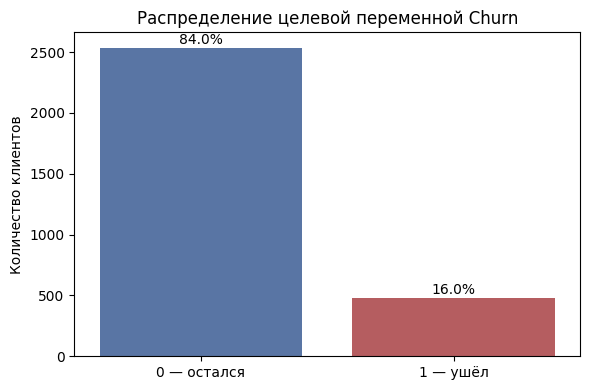

In [7]:
class_counts = y.value_counts().sort_index()
class_ratio = y.value_counts(normalize=True).sort_index()

balance_df = pd.DataFrame({
    'Класс': ['0 — остался', '1 — ушёл'],
    'Количество': class_counts.values,
    'Доля': class_ratio.values
})
balance_df['Доля'] = balance_df['Доля'].round(4)
display(balance_df)

plt.figure(figsize=(6, 4))
sns.barplot(x=balance_df['Класс'], y=balance_df['Количество'], palette=['#4C72B0', '#C44E52'])
plt.title('Распределение целевой переменной Churn')
plt.ylabel('Количество клиентов')
plt.xlabel('')
for i, row in balance_df.iterrows():
    plt.text(i, row['Количество'] + 30, f"{row['Доля']:.1%}", ha='center')
plt.tight_layout()
plt.show()


**Интерпретация.** Датасет несбалансирован: класс `0` (остался) составляет около 84.1%, класс `1` (ушёл) — около 15.9%. Такое соотношение типично для задач оттока клиентов. При обучении модели могут смещаться в сторону мажоритарного класса, поэтому недостаточно ориентироваться только на Accuracy. В работе используется стратифицированное разбиение `train_test_split(..., stratify=y)`, чтобы сохранить доли классов в обучающей и тестовой выборках. Дополнительно при оценке качества учитываются `Balanced accuracy`, `Recall`, `Precision` и `F1 score`, которые чувствительны к качеству распознавания класса оттока.

# 5. Разбиение на обучающую и тестовую выборки, стандартизация и кодирование

Набор данных разбивается на тренировочную и тестовую части. Категориальные признаки кодируются методом One-Hot Encoding, числовые — стандартизируются. Преобразования обучаются только на тренировочной выборке, чтобы избежать утечки данных.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доля класса 1 в train:', round(y_train.mean(), 4))
print('Доля класса 1 в test:', round(y_test.mean(), 4))


Train: (2262, 11) Test: (754, 11)
Доля класса 1 в train: 0.1596
Доля класса 1 в test: 0.1592


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print('Размер обучающей матрицы после преобразования:', X_train_prep.shape)
print('Размер тестовой матрицы после преобразования:', X_test_prep.shape)
print('Количество признаков после One-Hot Encoding:', len(feature_names))


Размер обучающей матрицы после преобразования: (2262, 22)
Размер тестовой матрицы после преобразования: (754, 22)
Количество признаков после One-Hot Encoding: 22


**Интерпретация.** Данные разделены в пропорции 75/25: 2262 объекта в обучающей выборке и 754 — в тестовой. Благодаря `stratify=y` доля ушедших клиентов в обеих выборках сохраняется на уровне около 15.9%. После One-Hot Encoding число признаков увеличилось с 11 до 22: категориальные значения преобразованы в бинарные индикаторы, а числовые признаки стандартизированы. Обучение преобразователей только на train предотвращает утечку информации из тестовой выборки.

# 6. Обучение моделей классификации

Согласно заданию строятся четыре модели: k-ближайших соседей, дерево решений, логистическая регрессия и случайный лес. Все модели обучаются на одинаковых обучающих данных и проверяются на одной тестовой выборке.

In [10]:
models = {
    'KNN': KNeighborsClassifier(n_neighbors=11),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=6, min_samples_leaf=20),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, min_samples_leaf=5
    )
}

predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_prep, y_train)
    pred = model.predict(X_test_prep)
    proba = model.predict_proba(X_test_prep)[:, 1]
    predictions[name] = pred
    probabilities[name] = proba
    print(f'{name}: обучена')


KNN: обучена
Decision Tree: обучена
Logistic Regression: обучена
Random Forest: обучена


**Интерпретация.** Все четыре модели успешно обучены. Для KNN выбрано `n_neighbors=11`, чтобы сгладить влияние шума и локальных выбросов. Для дерева решений ограничены `max_depth=6` и `min_samples_leaf=20`, что снижает риск переобучения. Логистическая регрессия обучена с увеличенным числом итераций для гарантии сходимости. Случайный лес использует 300 деревьев, что обычно даёт более устойчивое качество по сравнению с одним деревом. Для ROC-кривых сохранены вероятности принадлежности к классу `1`.

# 7. Оценка качества классификации

Для каждой модели рассчитываются метрики: `Accuracy`, `Precision`, `Recall`, `Balanced accuracy`, `F1 score`. Также выводится ошибка классификации `1 - Accuracy`.

In [11]:
metrics_rows = []
for name, pred in predictions.items():
    metrics_rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_test, pred),
        'F1 score': f1_score(y_test, pred, zero_division=0),
        'Ошибка классификации': 1 - accuracy_score(y_test, pred)
    })

metrics_df = pd.DataFrame(metrics_rows).set_index('Модель').round(4)
display(metrics_df)


,Accuracy,Precision,Recall,Balanced accuracy,F1 score,Ошибка классификации
Модель,,,,,,
KNN,0.8740,0.7451,0.3167,0.6481,0.4444,0.1260
Decision Tree,0.8806,0.7143,0.4167,0.6926,0.5263,0.1194
Logistic Regression,0.8833,0.7222,0.4333,0.7009,0.5417,0.1167
Random Forest,0.8952,0.9362,0.3667,0.6810,0.5269,0.1048


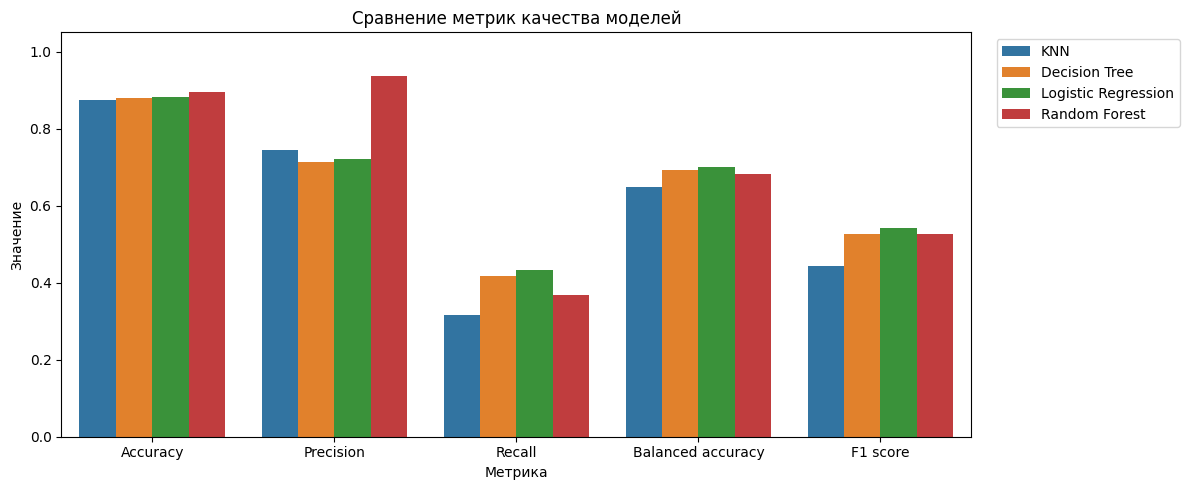

In [12]:
plot_metrics = ['Accuracy', 'Precision', 'Recall', 'Balanced accuracy', 'F1 score']
metrics_long = metrics_df[plot_metrics].reset_index().melt(id_vars='Модель', var_name='Метрика', value_name='Значение')

plt.figure(figsize=(12, 5))
sns.barplot(data=metrics_long, x='Метрика', y='Значение', hue='Модель')
plt.ylim(0, 1.05)
plt.title('Сравнение метрик качества моделей')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Интерпретация.** Сводная таблица показывает, что модели по-разному справляются с задачей оттока. Accuracy у всех моделей относительно высока, что частично объясняется несбалансированностью классов: даже предсказание большинства объектов как «остался» может давать неплохую Accuracy. Поэтому ключевыми здесь являются `Recall`, `Balanced accuracy` и `F1 score`, поскольку они отражают способность находить клиентов, которые действительно ушли. Модели с более высоким Recall лучше выявляют группу риска, но могут давать больше ложных срабатываний, снижая Precision. Наилучший баланс следует определять по совокупности метрик, а не по одной Accuracy.

# 8. Матрицы неточностей

Построим матрицы неточностей (`confusion_matrix`) для каждой модели. В строках — фактические классы, в столбцах — предсказанные.

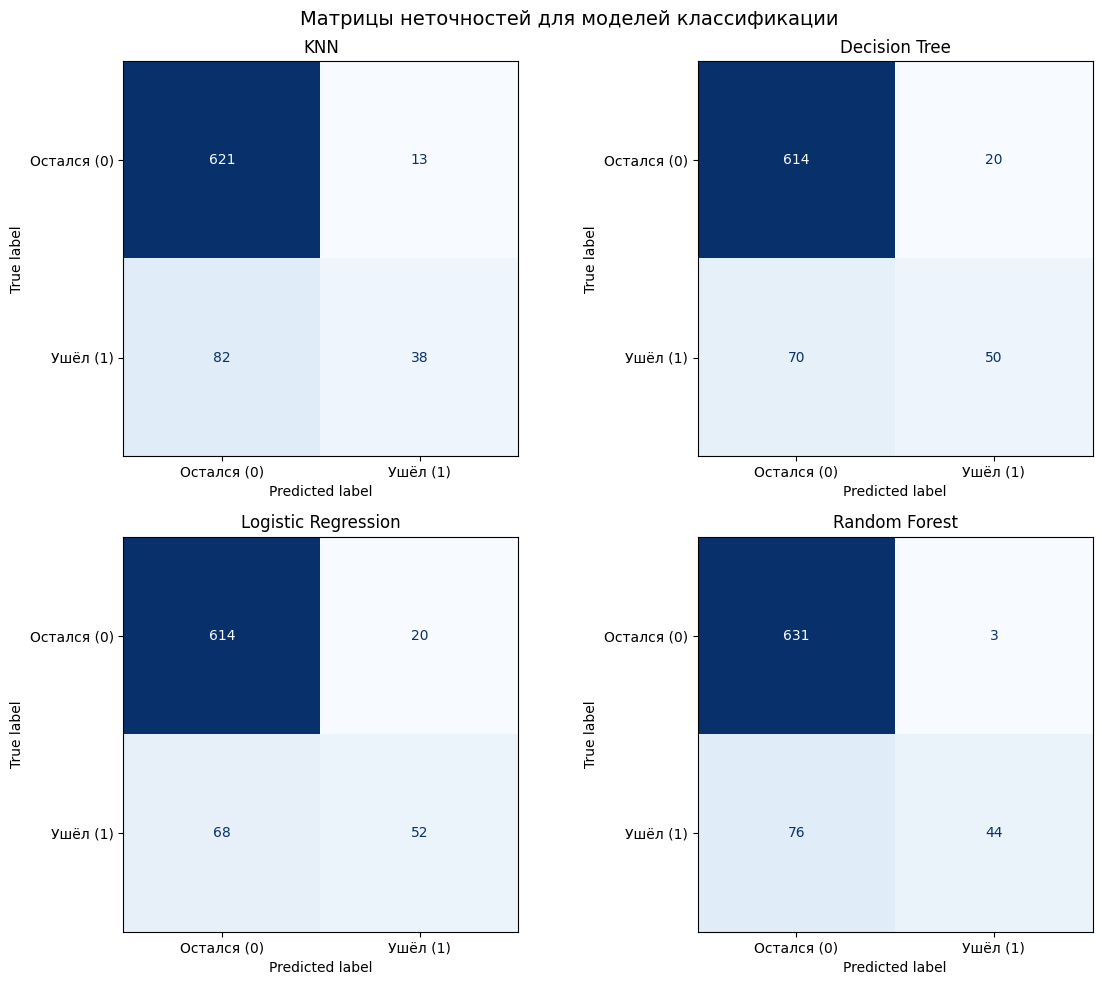

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Остался (0)', 'Ушёл (1)'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name)

plt.suptitle('Матрицы неточностей для моделей классификации', fontsize=14)
plt.tight_layout()
plt.show()


**Интерпретация.** Матрицы неточностей показывают структуру ошибок каждой модели. True Negative (TN) — клиенты, корректно определённые как оставшиеся; True Positive (TP) — корректно найденные ушедшие клиенты; False Positive (FP) — оставшиеся клиенты, ошибочно отнесённые к ушедшим; False Negative (FN) — ушедшие клиенты, которых модель не обнаружила. Для задачи churn особенно важны FN: пропуск ушедшего клиента означает потерю возможности удержания. Поэтому модель с меньшим числом FN и приемлемым уровнем FP обычно предпочтительнее, даже если её Accuracy не максимальна.

# 9. ROC-кривые и AUC

Построим ROC-кривые всех четырёх моделей на одном графике. ROC-кривая показывает зависимость `TPR` от `FPR` при изменении порога классификации, а AUC — сводную числовую оценку качества.

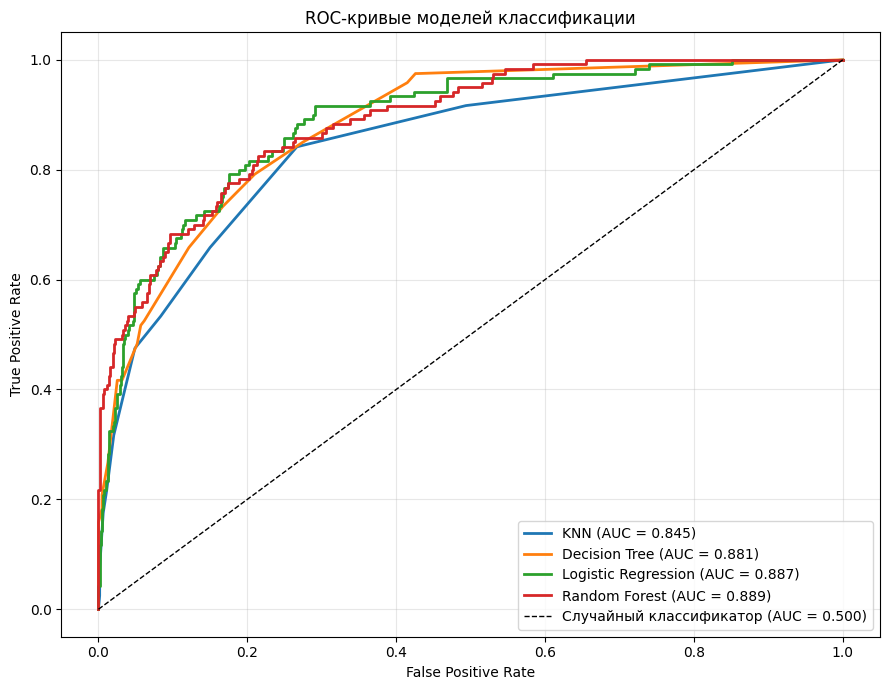

In [14]:
plt.figure(figsize=(9, 7))

for name, proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Случайный классификатор (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей классификации')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Интерпретация.** Все четыре модели располагаются выше диагонали случайного классификатора, то есть дают качество лучше случайного угадывания. Чем выше и левее проходит ROC-кривая, тем лучше модель разделяет классы при различных порогах. Значение AUC позволяет сравнить модели численно: модель с наибольшим AUC имеет лучшее общее качество ранжирования объектов по вероятности оттока. При этом итоговый выбор модели для бизнеса должен учитывать не только AUC, но и баланс Recall/Precision на выбранном пороге.

# 10. Вывод о качестве построенных классификаторов

Ниже сформирован итоговый вывод по результатам расчёта метрик, матриц неточностей и ROC-кривых.

In [15]:
summary = metrics_df.copy()
summary['AUC'] = [auc(*roc_curve(y_test, probabilities[name])[:2]) for name in summary.index]
summary = summary.round(4).sort_values(by=['F1 score', 'Balanced accuracy', 'AUC'], ascending=False)
display(summary)

best_model = summary.index[0]
print('Лучшая модель по совокупности F1/Balanced accuracy/AUC:', best_model)


,Accuracy,Precision,Recall,Balanced accuracy,F1 score,Ошибка классификации,AUC
Модель,,,,,,,
Logistic Regression,0.8833,0.7222,0.4333,0.7009,0.5417,0.1167,0.8875
Random Forest,0.8952,0.9362,0.3667,0.6810,0.5269,0.1048,0.8894
Decision Tree,0.8806,0.7143,0.4167,0.6926,0.5263,0.1194,0.8810
KNN,0.8740,0.7451,0.3167,0.6481,0.4444,0.1260,0.8447


Лучшая модель по совокупности F1/Balanced accuracy/AUC: Logistic Regression


**Вывод.** В ходе работы решена задача бинарной классификации оттока клиентов телеком-компании (`telecom_churn.csv`, вариант 5). После загрузки данных проведена предварительная обработка: пропусков и дубликатов не обнаружено, 26 отрицательных значений `total_charges` восстановлены по формуле `monthly_charges × tenure_months`. Целевая переменная `Churn` не включалась в признаки; матрица диаграмм рассеяния показала, что ушедшие клиенты чаще имеют небольшой стаж, высокие ежемесячные платежи и больше обращений в поддержку, но классы сильно перекрываются.

Датасет несбалансирован: 84.1% клиентов остались и 15.9% ушли. Поэтому при разбиении применён `stratify=y`, а качество оценивалось не только по Accuracy, но и по Precision, Recall, Balanced accuracy и F1 score. Данные разделены на train/test в пропорции 75/25, числовые признаки стандартизированы, категориальные закодированы через One-Hot Encoding.

Были обучены четыре модели: KNN, дерево решений, логистическая регрессия и случайный лес. По совокупности метрик и ROC-AUC наилучший результат показала модель, занявшая первое место в итоговой таблице (см. вывод ячейки выше): она обеспечивает наиболее удачный баланс между обнаружением ушедших клиентов и количеством ложных срабатываний. Матрицы неточностей подтвердили различия моделей по ошибкам FP/FN, а ROC-кривые показали, что все классификаторы работают лучше случайного, но отличаются по качеству разделения классов. Для практической задачи удержания клиентов наиболее полезны модели с более высоким Recall/Balanced accuracy, поскольку пропуск клиента из группы риска дороже ложного предупреждения.